In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/NEW/PRJNA339212")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,sample_group,Sample_ID,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,SRR4039959,AMPLICON,335,11948526,PRJNA339212,SAMN05583466,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",5185609,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:06:00Z,1,caries free-pre,A1,saliva 1,SRP082293
2,SRR4039960,AMPLICON,330,11161367,PRJNA339212,SAMN05583467,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",4726660,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:06:00Z,1,caries free-pre,A2,saliva 2,SRP082293
3,SRR4039961,AMPLICON,331,8234899,PRJNA339212,SAMN05583476,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",3514100,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:05:00Z,1,caries free-pre,A11,saliva 11,SRP082293
4,SRR4039962,AMPLICON,332,13381988,PRJNA339212,SAMN05583477,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",5764767,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:05:00Z,1,caries free-pre,A12,saliva 12,SRP082293
5,SRR4039963,AMPLICON,332,11134722,PRJNA339212,SAMN05583478,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",4736878,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:05:00Z,1,caries free-pre,A13,saliva 13,SRP082293
6,SRR4039964,AMPLICON,331,10880374,PRJNA339212,SAMN05583479,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",4671858,SICHUAN UNIVERSITY,2015,⋯,METAGENOMIC,oral metagenome,ILLUMINA,2016-08-23T00:00:00Z,2016-08-18T14:05:00Z,1,caries free-pre,A14,saliva 14,SRP082293


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "env_biome"                      "env_feature"                   
[17] "env_material"                   "Experiment"                    
[19] "geo_loc_name_country"           "geo_loc_name_country_continent"
[21] "geo_loc_name"                   "HOST"                          
[23] "Instrument"                     "lat_lon"                       
[25] "Library.Name"                   "LibraryLayout"                 
[27] "LibrarySelection"               "LibrarySource"                 
[29] "Organism"                       "Platform"                      
[31] "ReleaseDate"                    "create_date"                   
[33] "version"                        "sample_group"                  
[35] "Sample_ID"                      "Sample.Name"                   
[37] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$Sample_ID,
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = NA,
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$env_material,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = 'Ecological Effect of Arginine on Oral Microbiota',
    Disease_study = "YES",
    Status = initial_meta$sample_group,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 84
[1] 84


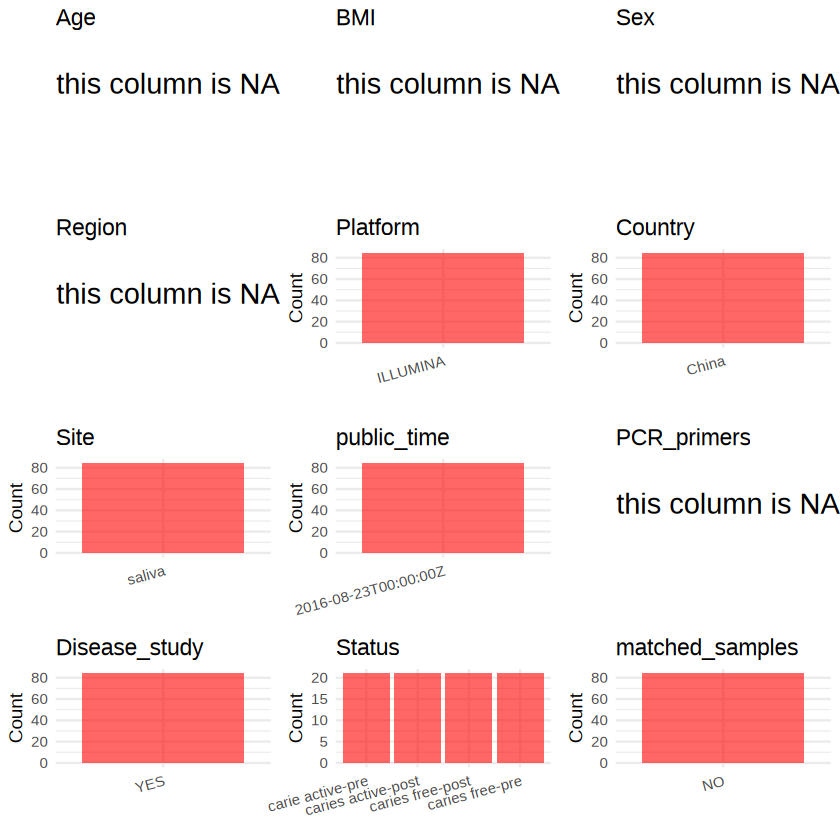

In [5]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [6]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", 
"Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status", "matched_samples")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/NEW/PRJNA339212/metadata.csv", quote = F)